In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from PIL import Image

In [ ]:
#sns.set_theme(style="white")

In [2]:
data = pd.read_csv("data.csv")
data = data[["condition", "task", "delay", "servo_kp", "seed",
             "reward_final", "reward_480", "actual_step", "steps_to_900", "steps_to_950"]]

In [3]:
data

,condition,task,delay,servo_kp,seed,reward_final,reward_480,actual_step,steps_to_900,steps_to_950
0,torque,WalkerWalk,0,0.0,42,977.392378,977.392378,4.802150e+08,38584320.0,48168960.0
1,torque,WalkerWalk,0,0.0,50,976.540289,976.540289,4.802150e+08,38584320.0,48168960.0
2,torque,WalkerWalk,0,0.0,51,976.887240,976.887240,4.802150e+08,38584320.0,48168960.0
3,torque,WalkerWalk,0,0.0,52,976.428334,976.428334,4.802150e+08,38584320.0,48168960.0
4,servo,WalkerWalk,0,0.5,50,145.401235,145.401235,4.802150e+08,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
93,torque,WalkerWalk,10,0.0,46,955.524053,947.933289,1.000243e+09,177684480.0,518553600.0
94,servo,WalkerWalk,10,64.0,51,949.951705,914.505693,1.000243e+09,245022720.0,806584320.0
95,servo,WalkerWalk,10,64.0,53,953.449502,874.860390,1.000243e+09,552222720.0,772915200.0
96,servo,WalkerWalk,10,64.0,54,947.205455,917.255721,1.000243e+09,201768960.0,926515200.0


In [20]:
data[data.servo_kp == 0].groupby("delay").reward_480.mean()

delay
0     977.395209
5     964.190504
7     954.199218
10    823.285870
Name: reward_480, dtype: float64

Text(48, 75, 'Task: Walker walk')

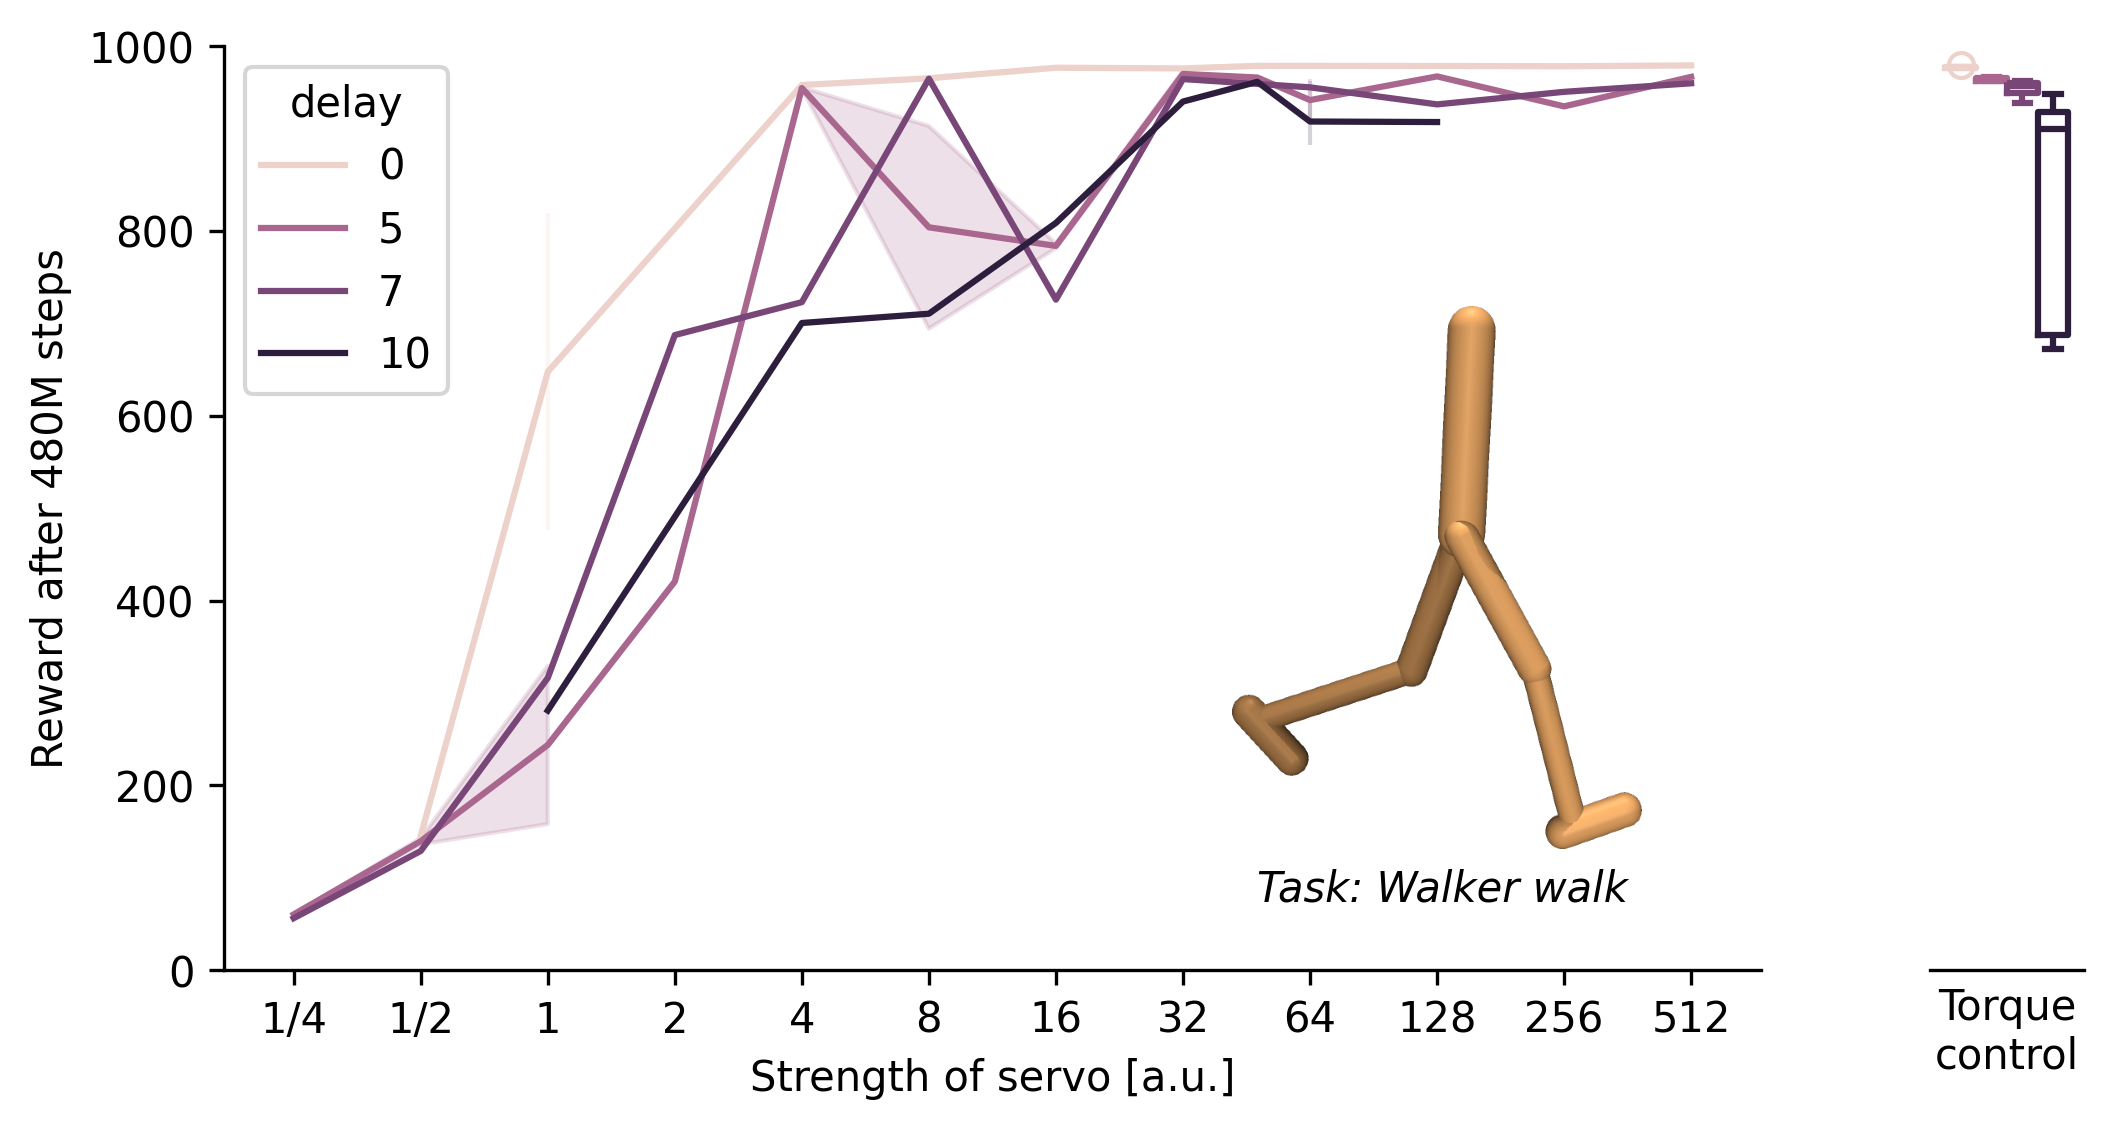

In [43]:
fig, axs = plt.subplots(1,2,gridspec_kw={"width_ratios": (10, 1)}, figsize=(8, 4), dpi=300)

sns.boxplot(data=data[data.servo_kp == 0],  y="reward_480", hue="delay", ax=axs[1], fill=False, legend=False)
axs[1].set_ylabel("")
axs[1].set_xlabel("Torque\ncontrol")
axs[1].set_xticks([])
axs[1].set_yticks([])
for ax in axs:
    ax.set_ylim(0, 1000)
sns.despine(ax=axs[1], left=True)

data_servo = data[data.servo_kp>0]
plt.sca(axs[0])
sns.lineplot(data=data_servo, x="servo_kp", y="reward_480", hue="delay", ax=axs[0])
plt.xscale("log")
sns.despine(ax=axs[0])
plt.xticks(2.0**np.arange(-2, 10), ["1/4", "1/2"] + list(2**np.arange(0,10)))
plt.xticks([], minor=True)
plt.xlabel("Strength of servo [a.u.]")
plt.ylabel("Reward after 480M steps")

im = Image.open(f"../three-arm-overview/illustrations/walker.png")
im = matplotlib.offsetbox.OffsetImage(im, zoom=0.2)
axs[0].add_artist(matplotlib.offsetbox.AnnotationBbox(im, (128, 425), frameon=False))
plt.text(48, 75, "Task: Walker walk", style="italic")

Text(0.37, 75000000.0, 'Task: Walker walk')

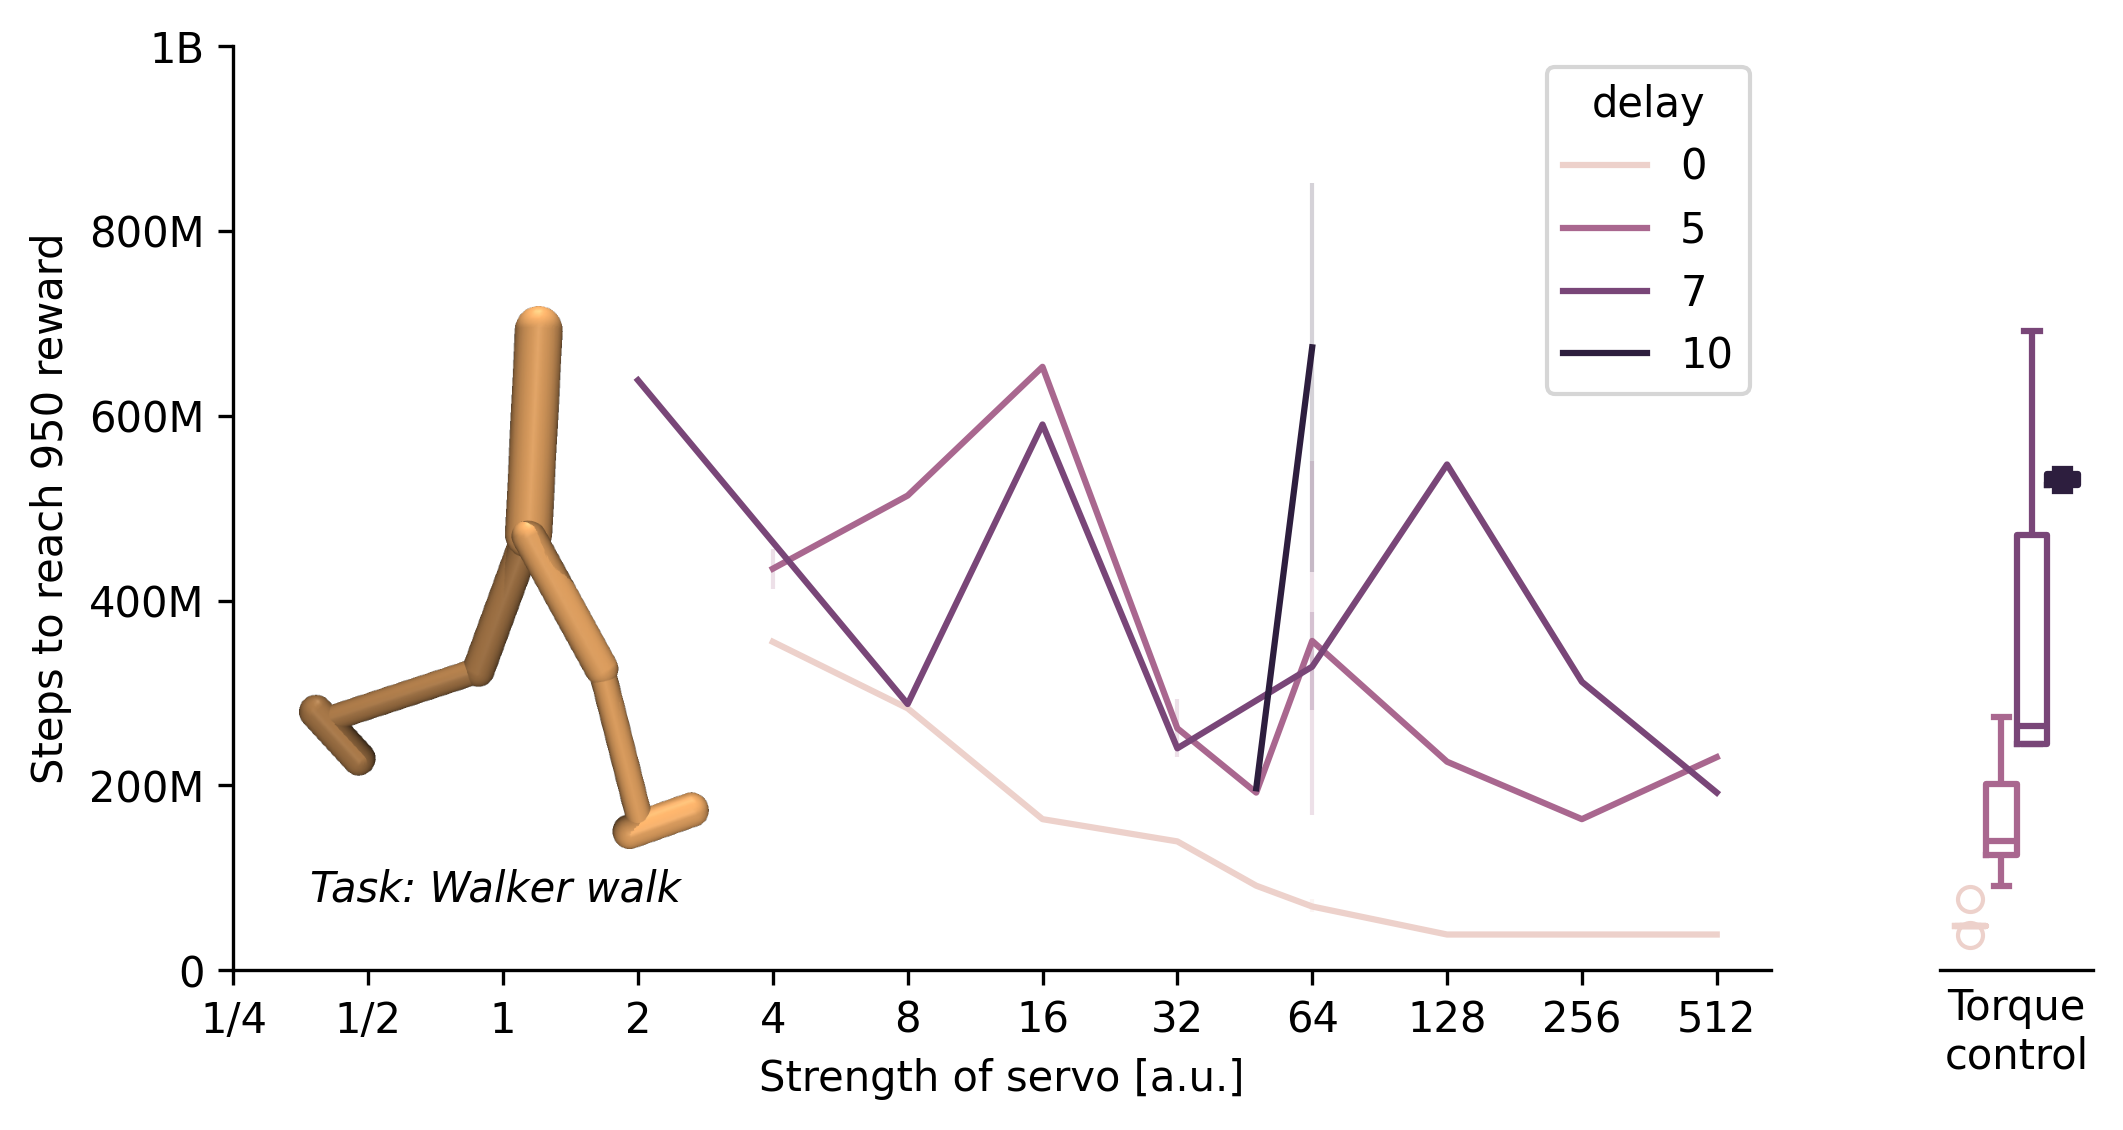

In [58]:
fig, axs = plt.subplots(1,2,gridspec_kw={"width_ratios": (10, 1)}, figsize=(8, 4), dpi=300)

sns.boxplot(data=data[data.servo_kp == 0],  y="steps_to_950", hue="delay", ax=axs[1], fill=False, legend=False)
axs[1].set_ylabel("")
axs[1].set_xlabel("Torque\ncontrol")
axs[1].set_xticks([])
axs[1].set_yticks([])
for ax in axs:
    ax.set_ylim(0, 1e9)
sns.despine(ax=axs[1], left=True)

data_servo = data[data.servo_kp>0]
plt.sca(axs[0])
sns.lineplot(data=data_servo, x="servo_kp", y="steps_to_950", hue="delay", ax=axs[0])
plt.xscale("log")
sns.despine(ax=axs[0])
plt.xticks(2.0**np.arange(-2, 10), ["1/4", "1/2"] + list(2**np.arange(0,10)))
plt.xticks([], minor=True)
plt.xlabel("Strength of servo [a.u.]")
plt.ylabel("Steps to reach 950 reward")
plt.yticks()
axs[0].set_yticks(np.arange(6)*2e8)
axs[0].set_yticklabels([0]+[f"{200*i}M" for i in range(1,5)]+["1B"])

im = Image.open(f"../three-arm-overview/illustrations/walker.png")
im = matplotlib.offsetbox.OffsetImage(im, zoom=0.2)
axs[0].add_artist(matplotlib.offsetbox.AnnotationBbox(im, (1, 4.25e8), frameon=False))
plt.text(0.37, 7.5e7, "Task: Walker walk", style="italic")